In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## Description des variables

Le jeu de données contient **1 000 trajets de taxi** décrits par **11 variables** : 10 variables explicatives et 1 variable cible (`Trip_Price`).

| Variable | Type | Description | Valeurs / plage observée |
|---|---|---|---|
| `Trip_Distance_km` | Numérique (continue) | Distance parcourue pendant le trajet, en kilomètres | 1,23 – 146,07 km (médiane ≈ 25,8) |
| `Time_of_Day` | Catégorielle | Moment de la journée où le trajet a lieu | `Morning`, `Afternoon`, `Evening`, `Night` |
| `Day_of_Week` | Catégorielle | Type de jour du trajet | `Weekday` (semaine), `Weekend` (week-end) |
| `Passenger_Count` | Numérique (discrète) | Nombre de passagers à bord | 1 – 4 |
| `Traffic_Conditions` | Catégorielle (ordinale) | Niveau de congestion du trafic | `Low`, `Medium`, `High` |
| `Weather` | Catégorielle | Conditions météorologiques pendant le trajet | `Clear` (dégagé), `Rain` (pluie), `Snow` (neige) |
| `Base_Fare` | Numérique (continue) | Tarif de prise en charge, fixe au démarrage de la course | 2,01 – 5,00 |
| `Per_Km_Rate` | Numérique (continue) | Tarif appliqué par kilomètre parcouru | 0,50 – 2,00 |
| `Per_Minute_Rate` | Numérique (continue) | Tarif appliqué par minute de trajet | 0,10 – 0,50 |
| `Trip_Duration_Minutes` | Numérique (continue) | Durée totale du trajet, en minutes | 5,01 – 119,84 min (médiane ≈ 61,9) |
| **`Trip_Price`** | Numérique (continue) | **Variable cible** : prix total payé pour la course | 6,13 – 332,04 (médiane ≈ 50,1) |


In [2]:
# Import les données
df= pd.read_csv("/content/sample_data/taxi_trip_pricing.csv")
df.head()

,Trip_Distance_km,Time_of_Day,Day_of_Week,Passenger_Count,Traffic_Conditions,Weather,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
0,19.35,Morning,Weekday,3.0,Low,Clear,3.56,0.80,0.32,53.82,36.2624
1,47.59,Afternoon,Weekday,1.0,High,Clear,NaN,0.62,0.43,40.57,NaN
2,36.87,Evening,Weekend,1.0,High,Clear,2.70,1.21,0.15,37.27,52.9032
3,30.33,Evening,Weekday,4.0,Low,NaN,3.48,0.51,0.15,116.81,36.4698
4,NaN,Evening,Weekday,3.0,High,Clear,2.93,0.63,0.32,22.64,15.6180


In [3]:
# Dimension des données
df.shape

(1000, 11)

In [4]:
# Afficher les infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Trip_Distance_km       950 non-null    float64
 1   Time_of_Day            950 non-null    object 
 2   Day_of_Week            950 non-null    object 
 3   Passenger_Count        950 non-null    float64
 4   Traffic_Conditions     950 non-null    object 
 5   Weather                950 non-null    object 
 6   Base_Fare              950 non-null    float64
 7   Per_Km_Rate            950 non-null    float64
 8   Per_Minute_Rate        950 non-null    float64
 9   Trip_Duration_Minutes  950 non-null    float64
 10  Trip_Price             951 non-null    float64
dtypes: float64(7), object(4)
memory usage: 86.1+ KB


### <font color = 'bisque'>Exploration et préparation des données

In [5]:
# sélection les variables quantitatives
quant = df.select_dtypes(include = 'number')
df.head()

,Trip_Distance_km,Time_of_Day,Day_of_Week,Passenger_Count,Traffic_Conditions,Weather,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
0,19.35,Morning,Weekday,3.0,Low,Clear,3.56,0.80,0.32,53.82,36.2624
1,47.59,Afternoon,Weekday,1.0,High,Clear,NaN,0.62,0.43,40.57,NaN
2,36.87,Evening,Weekend,1.0,High,Clear,2.70,1.21,0.15,37.27,52.9032
3,30.33,Evening,Weekday,4.0,Low,NaN,3.48,0.51,0.15,116.81,36.4698
4,NaN,Evening,Weekday,3.0,High,Clear,2.93,0.63,0.32,22.64,15.6180


In [6]:
# décrire les variables quantitatives
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Trip_Distance_km,950.0,27.070547,19.905300,1.2300,12.63250,25.8300,38.40500,146.067047
Passenger_Count,950.0,2.476842,1.102249,1.0000,1.25000,2.0000,3.00000,4.000000
Base_Fare,950.0,3.502989,0.870162,2.0100,2.73000,3.5200,4.26000,5.000000
Per_Km_Rate,950.0,1.233316,0.429816,0.5000,0.86000,1.2200,1.61000,2.000000
Per_Minute_Rate,950.0,0.292916,0.115592,0.1000,0.19000,0.2900,0.39000,0.500000
Trip_Duration_Minutes,950.0,62.118116,32.154406,5.0100,35.88250,61.8600,89.05500,119.840000
Trip_Price,951.0,56.874773,40.469791,6.1269,33.74265,50.0745,69.09935,332.043689


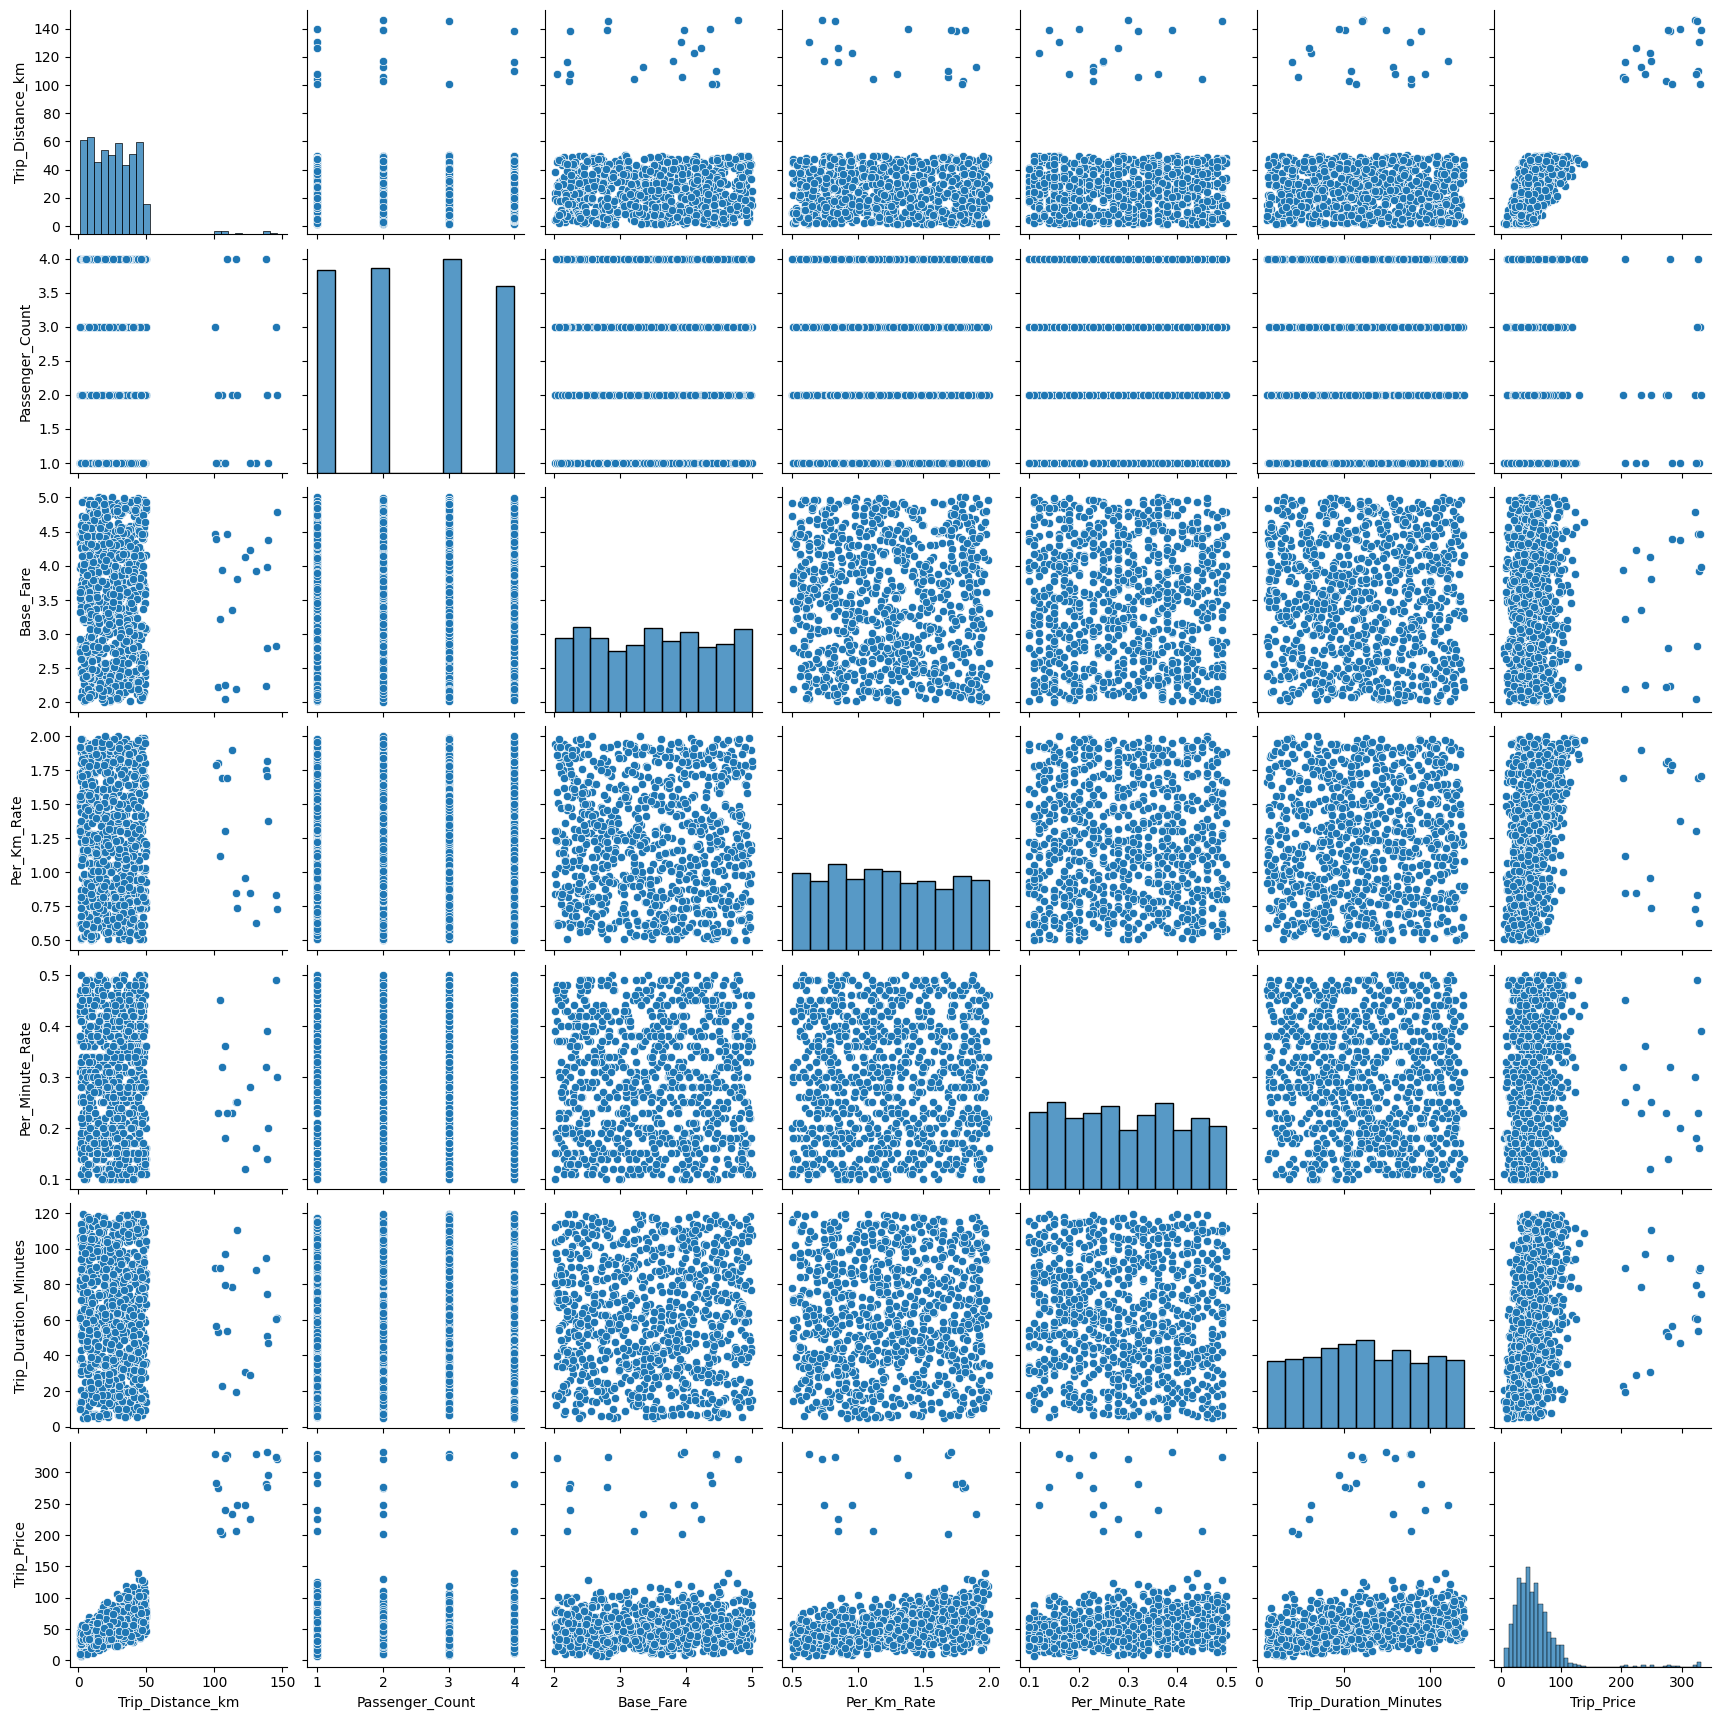

In [7]:
# pairplot des variables quantitatives
sns.pairplot(quant)
plt.show()

In [8]:
# Fonction permettant de visualiser les boxplots
def boxplot_func(col):
    fig = px.box(df,x = col)
    fig.show()

In [9]:
# Appliquer la fonctions boxplot_func
for col in quant.columns:
  boxplot_func(col)

In [10]:
# Afficher la matrice de corrélation
quant.corr()

,Trip_Distance_km,Passenger_Count,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
Trip_Distance_km,1.000000,-0.048397,0.032218,-0.017041,-0.025902,-0.022102,0.849123
Passenger_Count,-0.048397,1.000000,0.022932,0.030213,0.034068,0.022845,-0.014223
Base_Fare,0.032218,0.022932,1.000000,0.003092,-0.019150,0.012035,0.035533
Per_Km_Rate,-0.017041,0.030213,0.003092,1.000000,0.029241,0.027199,0.275135
Per_Minute_Rate,-0.025902,0.034068,-0.019150,0.029241,1.000000,-0.024230,0.141226
Trip_Duration_Minutes,-0.022102,0.022845,0.012035,0.027199,-0.024230,1.000000,0.221211
Trip_Price,0.849123,-0.014223,0.035533,0.275135,0.141226,0.221211,1.000000


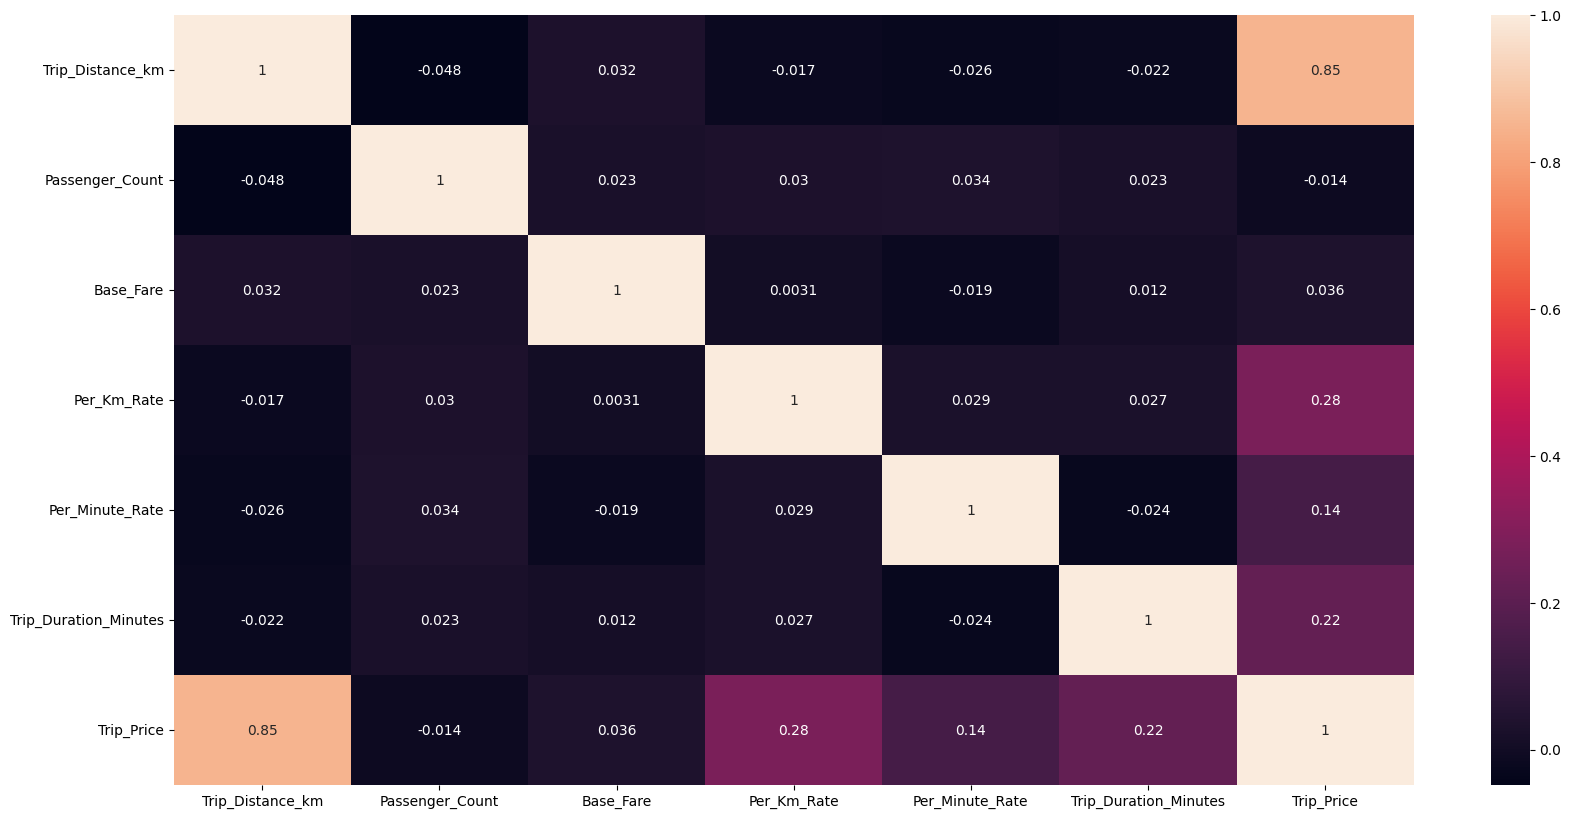

In [11]:
# Visualisaton le matrice de corrélation
plt.figure(figsize = (20, 10))
sns.heatmap(quant.corr(), annot = True)
plt.show()

In [12]:
# sélection les variables catégorielles
cat = df.select_dtypes(exclude = 'number')
df.head()

,Trip_Distance_km,Time_of_Day,Day_of_Week,Passenger_Count,Traffic_Conditions,Weather,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
0,19.35,Morning,Weekday,3.0,Low,Clear,3.56,0.80,0.32,53.82,36.2624
1,47.59,Afternoon,Weekday,1.0,High,Clear,NaN,0.62,0.43,40.57,NaN
2,36.87,Evening,Weekend,1.0,High,Clear,2.70,1.21,0.15,37.27,52.9032
3,30.33,Evening,Weekday,4.0,Low,NaN,3.48,0.51,0.15,116.81,36.4698
4,NaN,Evening,Weekday,3.0,High,Clear,2.93,0.63,0.32,22.64,15.6180


In [13]:
# Faire un describre
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Trip_Distance_km,950.0,27.070547,19.905300,1.2300,12.63250,25.8300,38.40500,146.067047
Passenger_Count,950.0,2.476842,1.102249,1.0000,1.25000,2.0000,3.00000,4.000000
Base_Fare,950.0,3.502989,0.870162,2.0100,2.73000,3.5200,4.26000,5.000000
Per_Km_Rate,950.0,1.233316,0.429816,0.5000,0.86000,1.2200,1.61000,2.000000
Per_Minute_Rate,950.0,0.292916,0.115592,0.1000,0.19000,0.2900,0.39000,0.500000
Trip_Duration_Minutes,950.0,62.118116,32.154406,5.0100,35.88250,61.8600,89.05500,119.840000
Trip_Price,951.0,56.874773,40.469791,6.1269,33.74265,50.0745,69.09935,332.043689


In [14]:
# Fonction de visualisaion du counplot
def countplot_func(col):
    val = cat[col].value_counts()
    fig = px.bar(x = val.index, y = val.values,color = val.index.astype(str), text_auto = True)
    fig.show()

In [15]:
# Appliquer la fonction countplot_func
for col in cat.columns:
  countplot_func(col)

In [16]:
# Imputer les valeurs manquantes des variables catégorielle en utilisant le mode
for col in cat.columns:
  df.fillna({col: df[col].mode()[0]}, inplace = True)

In [17]:
# Enregistrer les valeurs uniques des variables catégorielles dans un objet joblib
uniques = []
for col in cat.columns:
  uniques.append(np.unique(df[col]).tolist())
import os
# Créer le dossier s'il n'existe pas
os.makedirs('/content/model', exist_ok=True)
# sauvegarde
import joblib as jb
jb.dump(uniques, '/content/model/uniques.joblib')

['/content/model/uniques.joblib']

In [18]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
# Créer différents encodeurs pour les variables catégorielles
encoders = []
for i in range(len(cat.columns)):
  encoder = LabelEncoder()
  encoder.fit(df[cat.columns[i]]) # le modèle prend le temps de reconnaitre les classes
  df[cat.columns[i]] = encoder.transform(df[cat.columns[i]]) # encoder les valeurs
  # rajouter l'encoder sur la liste encoders
  encoders.append(encoder)

In [19]:
#afficher
df.head()

,Trip_Distance_km,Time_of_Day,Day_of_Week,Passenger_Count,Traffic_Conditions,Weather,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
0,19.35,2,0,3.0,1,0,3.56,0.80,0.32,53.82,36.2624
1,47.59,0,0,1.0,0,0,NaN,0.62,0.43,40.57,NaN
2,36.87,1,1,1.0,0,0,2.70,1.21,0.15,37.27,52.9032
3,30.33,1,0,4.0,1,0,3.48,0.51,0.15,116.81,36.4698
4,NaN,1,0,3.0,0,0,2.93,0.63,0.32,22.64,15.6180


In [20]:
import joblib as jb
# sauvegarde les encodeurs
jb.dump(encoders, '/content/model/encoders.joblib')

['/content/model/encoders.joblib']

In [21]:
from sklearn.impute import KNNImputer
# Imputer les valeurs manquantes des variables quantitatives
imputer = KNNImputer(n_neighbors=5)
df[:] = imputer.fit_transform(df)

In [22]:
# fonction d'imputation des valeurs aberrantes
def impute_func(df, col, n_neighbors=5):
    # 2. Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan # NaN
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [23]:
#Application du traitement
for col in quant.columns:
  impute_func(df, col)

In [24]:
# réafficher les boxplots
for col in quant.columns:
  boxplot_func(col)

In [25]:
# Fractionner les données
x = df.iloc[:,:-1].values
y = df.iloc[:, -1].values

In [26]:
# importer RobustScaler
from sklearn.preprocessing import RobustScaler
# Normaliser x
scaler = RobustScaler()
scaler.fit(x)
x = scaler.transform(x)

In [27]:
# sauvegarde du scaler
jb.dump(scaler, '/content/model/scaler.joblib')

['/content/model/scaler.joblib']

In [28]:
from sklearn.model_selection import train_test_split
# Splitter les données en train, val et test
x_train, x_vt,y_train,y_vt = train_test_split(x,y , test_size = 0.2, random_state = 42)
# Splitter les données en val et test
x_val, x_test, y_val, y_test = train_test_split(x_vt, y_vt, test_size = 0.5, random_state = 42)

### <font color = 'bisque'>Multiple Linear Regression

In [29]:
# Rechercher les paramètres optimaux de l'algorithme
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import LinearRegression

# Validation croisée et figé
cv = KFold(n_splits=5, shuffle=True, random_state=42)
# dictionnaire params
params_lr = {
    'fit_intercept': [True, False], #b=0
    'positive': [True, False] #true = valeur +, false = valeur + et -
 }
# Initialisation du modèle
lr = LinearRegression()
# Initialisation du GridSearchCV
grid_lr = GridSearchCV(lr, params_lr, cv = cv)
# Lancer la recherche
grid_lr.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=LinearRegression(),
             param_grid={'fit_intercept': [True, False],
                         'positive': [True, False]})

In [30]:
# Récupérer le modèle optimal en partant de gridsearch
lr_model = grid_lr.best_estimator_

#### <font color = 'teal'> Evaluation du Linear Regression<font>

In [31]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error,root_mean_squared_error
# Calculer le R2 score et Mean Squarred Error
# from math import *
def evaluation(model):
  y_pred = model.predict(x_val)
  r2 = r2_score(y_val, y_pred)
  mse = mean_squared_error(y_val, y_pred)
  mae = mean_absolute_error(y_val, y_pred)
  rmse = root_mean_squared_error(y_val, y_pred)
  return r2, mse, mae, rmse

In [32]:
r2_lr, mse_lr, mae_lr, rmse_lr = evaluation(lr_model)
print(f"R2 : {r2_lr} --MSE : {mse_lr}  --RMSE : {rmse_lr} --MAE : {mae_lr}")

R2 : 0.864514089167485 --MSE : 71.61888514466979  --RMSE : 8.462794168870573 --MAE : 6.725709389585957


### <font color = 'bisque'>Ridge Regression

In [33]:
# Rechercher les paramètres optimaux de l'algorithme
from sklearn.linear_model import Ridge
# dictionnaire params
params_rr = {
    'fit_intercept': [True, False],
    'positive': [True, False],
    'alpha':np.logspace(-8,8, 100) #
 }
# Initialisation du modèle
rr = Ridge()
# Initialisation du GridSearchCV
grid_rr = GridSearchCV(rr, params_rr, cv = cv)
# Lancer la recherche
grid_rr.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Ridge(),
             param_grid={'alpha': array([1.00000000e-08, 1.45082878e-08, 2.10490414e-08, 3.05385551e-08,
       4.43062146e-08, 6.42807312e-08, 9.32603347e-08, 1.35304777e-07,
       1.96304065e-07, 2.84803587e-07, 4.13201240e-07, 5.99484250e-07,
       8.69749003e-07, 1.26185688e-06, 1.83073828e-06, 2.65608778e-06,
       3....
       8.49753436e+04, 1.23284674e+05, 1.78864953e+05, 2.59502421e+05,
       3.76493581e+05, 5.46227722e+05, 7.92482898e+05, 1.14975700e+06,
       1.66810054e+06, 2.42012826e+06, 3.51119173e+06, 5.09413801e+06,
       7.39072203e+06, 1.07226722e+07, 1.55567614e+07, 2.25701972e+07,
       3.27454916e+07, 4.75081016e+07, 6.89261210e+07, 1.00000000e+08]),
                         'fit_intercept': [True, False],
                         'positive': [True, False]})

In [34]:
# Récupérer le modèle optimal en partant de gridsearch
rr_model = grid_rr.best_estimator_

#### <font color = 'teal'> Evaluation du Ridge<font>

In [35]:
# Evaluation le modèle
r2_rr, mse_rr, mae_rr, rmse_rr = evaluation(rr_model)
print(f"R2 : {r2_rr} --MSE : {mse_rr}  --RMSE : {rmse_rr} --MAE : {mae_rr}")

R2 : 0.8642675279829386 --MSE : 71.7492192661194  --RMSE : 8.470491087659521 --MAE : 6.733627977911116


### <font color = 'bisque'>Decision Tree Regressor<font>

In [36]:
# Recherche des paramètres optimaux du decision tree
from sklearn.tree import DecisionTreeRegressor
# Dictionaire des params
params_dt = {
    'max_depth':np.arange(1,30),
    'criterion':['squared_error', 'absolute_error']
}
# Initialisation du modèle
dt = DecisionTreeRegressor(random_state = 42)
# Initialisation du GridSearchCV
grid_dt = GridSearchCV(dt, params_dt, cv = cv)
# Lancer la recherche
grid_dt.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=DecisionTreeRegressor(random_state=42),
             param_grid={'criterion': ['squared_error', 'absolute_error'],
                         'max_depth': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29])})

In [37]:
# Récupérer le modèle optimal en partant de gridsearch
dt_model = grid_dt.best_estimator_

#### <font color = 'teal'> Evaluation du Decision Tree Regressor<font>

In [38]:
# Evaluation le modèle
r2_dt, mse_dt, mae_dt, rmse_dt = evaluation(dt_model)
print(f"R2 : {r2_dt} --MSE : {mse_dt}  --RMSE : {rmse_dt} --MAE : {mae_dt}")

R2 : 0.7921831661197742 --MSE : 109.85356237664904  --RMSE : 10.481105016965007 --MAE : 8.01475512


### <font color = 'bisque'>Random Forest Regressor<font>

In [39]:
from sklearn.ensemble import RandomForestRegressor

# Dictionnaires des paramètres
params_rf = {
    'n_estimators':np.arange(10,100,10),
    'max_depth':np.arange(1,15)
}
# Initialisation du modèle
rf =  RandomForestRegressor()
# Objet grid
grid_rf = GridSearchCV(rf, params_rf, cv=cv)
# Lancer la recherche
grid_rf.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestRegressor(),
             param_grid={'max_depth': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14]),
                         'n_estimators': array([10, 20, 30, 40, 50, 60, 70, 80, 90])})

In [40]:
# Récupérer le modèle optimal en partant de gridsearch
rf_model = grid_rf.best_estimator_

#### <font color = 'teal'> Evaluation du Random Forest<font>

In [41]:
# Evaluation le modèle
r2_rf, mse_rf, mae_rf, rmse_rf = evaluation(rf_model)
print(f"R2 : {r2_rf} --MSE : {mse_rf}  --RMSE : {rmse_rf} --MAE : {mae_rf}")

R2 : 0.9032765182737211 --MSE : 51.12876967045103  --RMSE : 7.150438425051364 --MAE : 5.208552637405274


In [42]:
# comparaison des métriques
list_names = ['LR', 'RR', 'DT', 'RF']
list_r2 = [r2_lr, r2_rr, r2_dt, r2_rf]
list_mse = [mse_lr, mse_rr, mse_dt, mse_rf]
list_mae = [mae_lr, mae_rr, mae_dt, mae_rf]
list_rmse = [rmse_lr, rmse_rr, rmse_dt, rmse_rf]
list_final = [list_r2, list_mse, list_mae, list_rmse]
for i in range(4):
  fig = px.bar(y = list_names, x = list_final[i], color= list_names, text_auto = True)
  fig.show()

In [43]:
# télécharger le modèle le plus performant
jb.dump(rf_model, '/content/model/rf_model.joblib')

['/content/model/rf_model.joblib']

### <font color = 'bisque'>Tester le modèle le plus performant<font>

In [44]:
#  echantillon des données test
x_test_10 = x_test[:10]
y_test_10 = y_test[:10]
# Prédictions
y_pred_10 = rf_model.predict(x_test_10)
# Parcourir les prédictions
for i in range(10):
  print(f"Prédiction {i + 1} : {y_pred_10[i]:.2f}$ --Réel :{y_test_10[i]:.2f}$")

Prédiction 1 : 11.84$ --Réel :13.06$
Prédiction 2 : 14.02$ --Réel :12.73$
Prédiction 3 : 76.33$ --Réel :86.90$
Prédiction 4 : 27.74$ --Réel :29.86$
Prédiction 5 : 52.88$ --Réel :57.08$
Prédiction 6 : 48.84$ --Réel :46.81$
Prédiction 7 : 41.27$ --Réel :40.36$
Prédiction 8 : 71.05$ --Réel :81.85$
Prédiction 9 : 29.67$ --Réel :27.16$
Prédiction 10 : 52.55$ --Réel :54.44$
